# Theory Gate: Informatively Stopped Hierarchical Label Refinement

This CPU-only notebook tests the mathematical core of the proposed project
before any expensive image-model training. It asks:

1. Can different fine-label distributions produce the same observed refined labels?
2. Do hierarchy-aware sensitivity assumptions provide valid, useful bounds?
3. Can observations at multiple refinement horizons tighten those bounds?
4. Can a worst-case classifier be safer than training only on refined labels?

The experiment is synthetic by design: the latent truth is known, so every
identification claim can be checked exactly. Runtime is normally below one minute.



In [1]:
from pathlib import Path
import json
import math
import shutil
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

SEED = 20261004
N = 60_000
GAMMAS = [1.0, 2.0, 4.0, 8.0, 16.0, np.inf]
GRID_SIZE = 50_001

rng = np.random.default_rng(SEED)
OUT = Path("selective_refinement_theory_gate_results")
OUT.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Output directory:", OUT.resolve())



Python: 3.13.5
NumPy: 2.3.5
Output directory: /mnt/data/repo_exec/theory/selective_refinement_theory_gate_results


## 1. Observation model

The hierarchy has four leaves:

- ROOT
  - A
    - A1
    - A2
  - B
    - B1
    - B2

Every item has a latent leaf `Y`. At the first checkpoint it may remain at
`ROOT` or reach its correct parent. At later checkpoints it may remain at the
parent or reach its exact leaf. Refinement probabilities depend on the latent
leaf and features, creating informative stopping.



In [2]:
LEAVES = np.array(["A1", "A2", "B1", "B2"])
PARENT = {"A1": "A", "A2": "A", "B1": "B", "B2": "B"}

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    ez = np.exp(z)
    return ez / ez.sum(axis=1, keepdims=True)

x = rng.normal(size=N)
logits = np.column_stack([
    0.65 + 1.10 * x,   # A1
    0.25 - 0.80 * x,   # A2
   -0.10 + 0.35 * x,   # B1
    0.00 - 0.25 * x,   # B2
])
leaf_prob = softmax(logits)
y_idx = np.array([rng.choice(4, p=p) for p in leaf_prob])
y = LEAVES[y_idx]
parent = np.array([PARENT[v] for v in y])

# Stage 1: ROOT -> correct parent, or stop at ROOT.
stage1_leaf_effect = np.array([0.35, -0.10, 0.15, -0.25])
p_parent = sigmoid(1.00 - 0.25 * np.abs(x) + stage1_leaf_effect[y_idx])
reached_parent = rng.random(N) < p_parent
label_t1 = np.where(reached_parent, parent, "ROOT")

# Stage 2, early horizon: correct parent -> exact leaf.
# A1 is deliberately harder to refine than A2.
early_leaf_effect = np.array([-1.15, 1.05, -0.45, 0.55])
p_early = sigmoid(-0.80 + 0.20 * x - 0.10 * np.abs(x) + early_leaf_effect[y_idx])
refined_early = reached_parent & (rng.random(N) < p_early)
label_t2 = np.where(refined_early, y, label_t1)

# Stage 3, late horizon: unresolved parent labels get another chance.
# The second wave partly compensates for the early disparity. This makes the
# early and late checkpoints impose genuinely different sensitivity constraints.
late_leaf_effect = np.array([1.20, -0.20, 0.45, -0.10])
p_late_additional = sigmoid(-0.10 + 0.10 * x + late_leaf_effect[y_idx])
refined_late = refined_early | (
    reached_parent & (~refined_early) & (rng.random(N) < p_late_additional)
)
label_t3 = np.where(refined_late, y, label_t1)

# Structural checks: a trajectory can only stay put or move downward.
assert np.all(~refined_early | reached_parent)
assert np.all(~refined_early | refined_late)
assert np.all((label_t1 == "ROOT") | (label_t1 == parent))
assert np.all((label_t3 == "ROOT") | (label_t3 == parent) | (label_t3 == y))

df = pd.DataFrame({
    "x": x,
    "true_leaf": y,
    "true_parent": parent,
    "label_t1": label_t1,
    "label_t2": label_t2,
    "label_t3": label_t3,
    "reached_parent": reached_parent,
    "refined_early": refined_early,
    "refined_late": refined_late,
})

trajectory_summary = pd.DataFrame({
    "checkpoint": ["t1", "t2", "t3"],
    "root_fraction": [(label_t1 == "ROOT").mean(),
                      (label_t2 == "ROOT").mean(),
                      (label_t3 == "ROOT").mean()],
    "parent_fraction": [
        np.isin(label_t1, ["A", "B"]).mean(),
        np.isin(label_t2, ["A", "B"]).mean(),
        np.isin(label_t3, ["A", "B"]).mean(),
    ],
    "leaf_fraction": [
        np.isin(label_t1, LEAVES).mean(),
        np.isin(label_t2, LEAVES).mean(),
        np.isin(label_t3, LEAVES).mean(),
    ],
})
display(trajectory_summary.round(4))



,checkpoint,root_fraction,parent_fraction,leaf_fraction
0,t1,0.2951,0.7049,0.0000
1,t2,0.2951,0.4990,0.2060
2,t3,0.2951,0.1870,0.5179


## 2. Hierarchy-only sharp bounds

Without assumptions about refinement, an unresolved internal node may contain
any descendant leaf. Consequently, the lower bound for a leaf is its exactly
observed mass, while its upper bound adds every unresolved ancestor mass that
could contain it. These are sharp bounds: every value inside them can be
produced by a compatible allocation of unresolved observations.



In [3]:
final_labels = pd.Series(label_t3)
mass = final_labels.value_counts(normalize=True).to_dict()
true_mass = pd.Series(y).value_counts(normalize=True).to_dict()

rows = []
for leaf in LEAVES:
    par = PARENT[leaf]
    lower = mass.get(leaf, 0.0)
    upper = lower + mass.get(par, 0.0) + mass.get("ROOT", 0.0)
    truth = true_mass.get(leaf, 0.0)
    rows.append({
        "leaf": leaf,
        "lower": lower,
        "truth": truth,
        "upper": upper,
        "width": upper - lower,
        "contains_truth": lower - 1e-12 <= truth <= upper + 1e-12,
    })

hierarchy_bounds = pd.DataFrame(rows)
assert hierarchy_bounds["contains_truth"].all()
display(hierarchy_bounds.round(4))

revealed = np.isin(label_t3, LEAVES)
naive_leaf_mass = pd.Series(y[revealed]).value_counts(normalize=True).reindex(LEAVES, fill_value=0)
truth_leaf_mass = pd.Series(y).value_counts(normalize=True).reindex(LEAVES, fill_value=0)
bias_table = pd.DataFrame({
    "leaf": LEAVES,
    "true_prevalence": truth_leaf_mass.values,
    "naive_among_refined": naive_leaf_mass.values,
})
bias_table["absolute_bias"] = (
    bias_table["naive_among_refined"] - bias_table["true_prevalence"]
).abs()
display(bias_table.round(4))



,leaf,lower,truth,upper,width,contains_truth
0,A1,0.2365,0.3938,0.6489,0.4124,True
1,A2,0.1373,0.2902,0.5498,0.4124,True
2,B1,0.0698,0.1437,0.4346,0.3647,True
3,B2,0.0742,0.1723,0.4389,0.3647,True


,leaf,true_prevalence,naive_among_refined,absolute_bias
0,A1,0.3938,0.4566,0.0628
1,A2,0.2902,0.2652,0.0250
2,B1,0.1437,0.1349,0.0089
3,B2,0.1723,0.1434,0.0290


## 3. Constructive non-identifiability proof inside parent A

Restrict attention to items known to belong to parent A at `t1`. At a chosen
horizon, define

\[
a=P(R=1,Y=A1),\qquad b=P(R=1,Y=A2).
\]

The latent prevalence \(p=P(Y=A1)\) can be any value in
\([a,1-b]\). For any candidate \(p\), choosing
\(\pi_1=a/p\) and \(\pi_2=b/(1-p)\) reproduces exactly the same observed data.



In [4]:
cohort_A = reached_parent & (parent == "A")
n_A = int(cohort_A.sum())

def observed_masses(refined_mask):
    a = np.mean(refined_mask[cohort_A] & (y[cohort_A] == "A1"))
    b = np.mean(refined_mask[cohort_A] & (y[cohort_A] == "A2"))
    return float(a), float(b)

a_early, b_early = observed_masses(refined_early)
a_late, b_late = observed_masses(refined_late)
p_true_A1 = float(np.mean(y[cohort_A] == "A1"))

nonid_lower, nonid_upper = a_late, 1.0 - b_late
assert nonid_lower <= p_true_A1 <= nonid_upper

candidate_ps = np.linspace(nonid_lower + 1e-6, nonid_upper - 1e-6, 5)
construction = []
for p in candidate_ps:
    pi1 = a_late / p
    pi2 = b_late / (1.0 - p)
    construction.append({
        "candidate_P_A1": p,
        "P_refine_given_A1": pi1,
        "P_refine_given_A2": pi2,
        "reconstructed_a": p * pi1,
        "reconstructed_b": (1.0 - p) * pi2,
    })

construction = pd.DataFrame(construction)
assert np.allclose(construction["reconstructed_a"], a_late)
assert np.allclose(construction["reconstructed_b"], b_late)

print(f"A cohort size: {n_A:,}")
print(f"True P(A1 | reached A): {p_true_A1:.4f}")
print(f"No-assumption identified set: [{nonid_lower:.4f}, {nonid_upper:.4f}]")
print(f"Identified-set width: {nonid_upper - nonid_lower:.4f}")
display(construction.round(4))



A cohort size: 29,472
True P(A1 | reached A): 0.6075
No-assumption identified set: [0.4815, 0.7204]
Identified-set width: 0.2389


,candidate_P_A1,P_refine_given_A1,P_refine_given_A2,reconstructed_a,reconstructed_b
0,0.4815,1.0000,0.5392,0.4815,0.2796
1,0.5412,0.8896,0.6094,0.4815,0.2796
2,0.6009,0.8012,0.7006,0.4815,0.2796
3,0.6607,0.7288,0.8240,0.4815,0.2796
4,0.7204,0.6683,1.0000,0.4815,0.2796


## 4. Sensitivity bounds

We bound informative refinement using an odds-ratio parameter \(\Gamma\):

\[
\Gamma^{-1}\leq
\frac{\pi_1/(1-\pi_1)}{\pi_2/(1-\pi_2)}
\leq\Gamma.
\]

`Gamma = 1` means equal refinement odds within the parent. Larger values allow
stronger dependence on the hidden leaf. `Gamma = infinity` returns the
hierarchy-only non-identification interval.



In [5]:
def sensitivity_interval(observations, gamma, grid_size=GRID_SIZE):
    """Return the feasible interval for p=P(A1) across one or more horizons.

    observations is a list of (a_h, b_h), where a_h=P(R_h=1,Y=A1)
    and b_h=P(R_h=1,Y=A2) within the same parent cohort.
    """
    lo = max(a for a, _ in observations)
    hi = min(1.0 - b for _, b in observations)
    if hi < lo:
        return (np.nan, np.nan)
    if np.isinf(gamma):
        return (lo, hi)

    eps = 1e-10
    grid = np.linspace(lo + eps, hi - eps, grid_size)
    feasible = np.ones(grid.size, dtype=bool)
    for a, b in observations:
        pi1 = a / grid
        pi2 = b / (1.0 - grid)
        valid = (pi1 > 0) & (pi1 < 1) & (pi2 > 0) & (pi2 < 1)
        odds_ratio = np.full_like(grid, np.nan)
        odds_ratio[valid] = (
            (pi1[valid] / (1.0 - pi1[valid])) /
            (pi2[valid] / (1.0 - pi2[valid]))
        )
        feasible &= valid & (odds_ratio >= 1.0 / gamma) & (odds_ratio <= gamma)

    if not feasible.any():
        return (np.nan, np.nan)
    vals = grid[feasible]
    return (float(vals[0]), float(vals[-1]))

bound_rows = []
for gamma in GAMMAS:
    late_only = sensitivity_interval([(a_late, b_late)], gamma)
    two_horizon = sensitivity_interval(
        [(a_early, b_early), (a_late, b_late)], gamma
    )
    for design, interval in [("late_only", late_only), ("two_horizons", two_horizon)]:
        lower, upper = interval
        bound_rows.append({
            "gamma": gamma,
            "design": design,
            "lower": lower,
            "truth": p_true_A1,
            "upper": upper,
            "width": upper - lower if np.isfinite(lower) else np.nan,
            "contains_truth": (
                np.isfinite(lower) and lower <= p_true_A1 <= upper
            ),
        })

sensitivity_bounds = pd.DataFrame(bound_rows)
display(sensitivity_bounds.round(4))

# Data generated under unrestricted feature-dependent refinement need not be
# compatible with small Gamma values. This is a feature, not an error: empty or
# truth-excluding intervals diagnose an overly strong sensitivity assumption.



,gamma,design,lower,truth,upper,width,contains_truth
0,1.0,late_only,NaN,0.6075,NaN,NaN,False
1,1.0,two_horizons,NaN,0.6075,NaN,NaN,False
2,2.0,late_only,0.5920,0.6075,0.6666,0.0746,True
3,2.0,two_horizons,NaN,0.6075,NaN,NaN,False
4,4.0,late_only,0.5534,0.6075,0.6901,0.1367,True
5,4.0,two_horizons,NaN,0.6075,NaN,NaN,False
6,8.0,late_only,0.5238,0.6075,0.7042,0.1804,True
7,8.0,two_horizons,0.5238,0.6075,0.6255,0.1017,True
8,16.0,late_only,0.5047,0.6075,0.7120,0.2073,True
9,16.0,two_horizons,0.5047,0.6075,0.6999,0.1952,True


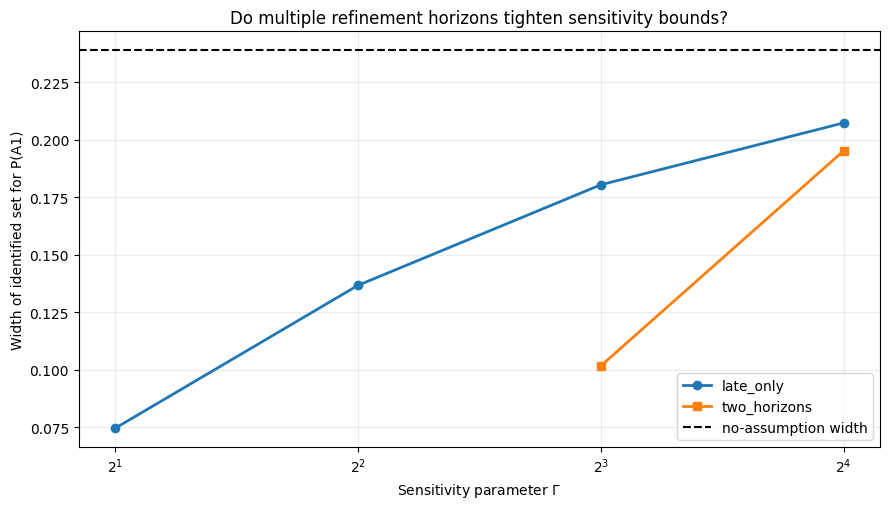

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.2))
finite_gamma = [g for g in GAMMAS if np.isfinite(g)]
for design, marker in [("late_only", "o"), ("two_horizons", "s")]:
    part = sensitivity_bounds[
        (sensitivity_bounds.design == design) &
        (sensitivity_bounds.gamma.isin(finite_gamma))
    ]
    ax.plot(part.gamma, part.width, marker=marker, linewidth=2, label=design)
ax.axhline(nonid_upper - nonid_lower, color="black", linestyle="--",
           label="no-assumption width")
ax.set_xscale("log", base=2)
ax.set_xlabel(r"Sensitivity parameter $\Gamma$")
ax.set_ylabel("Width of identified set for P(A1)")
ax.set_title("Do multiple refinement horizons tighten sensitivity bounds?")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "sensitivity_bound_widths.png", dpi=180)
plt.show()



## 5. Feature-conditional robust classification

We now divide the feature axis into bins. Within each bin, a naive classifier
uses only refined labels. A sensitivity-aware classifier chooses the class
with smaller worst-case 0-1 loss over the identified interval. This is not the
final proposed algorithm; it is a falsifiable demonstration that partial
identification can change decisions.



In [7]:
def choose_robust_class(lower, upper):
    # Predict A1: worst-case error is 1-lower.
    # Predict A2: worst-case error is upper.
    return "A1" if (1.0 - lower) <= upper else "A2"

sub = df.loc[cohort_A].copy()
sub["bin"] = pd.qcut(sub["x"], q=10, labels=False, duplicates="drop")
chosen_gamma = 16.0
decision_rows = []

for bin_id, g in sub.groupby("bin", observed=True):
    n = len(g)
    true_p = np.mean(g.true_leaf == "A1")
    early_a = np.mean(g.refined_early & (g.true_leaf == "A1"))
    early_b = np.mean(g.refined_early & (g.true_leaf == "A2"))
    late_a = np.mean(g.refined_late & (g.true_leaf == "A1"))
    late_b = np.mean(g.refined_late & (g.true_leaf == "A2"))
    revealed_total = late_a + late_b
    naive_p = late_a / revealed_total if revealed_total > 0 else 0.5
    lower, upper = sensitivity_interval(
        [(early_a, early_b), (late_a, late_b)], chosen_gamma,
        grid_size=20_001,
    )
    if not np.isfinite(lower):
        # Explicit fallback: no decision if the selected Gamma is contradicted.
        robust_pred = None
    else:
        robust_pred = choose_robust_class(lower, upper)
    naive_pred = "A1" if naive_p >= 0.5 else "A2"
    naive_worst_error = (1.0 - lower) if naive_pred == "A1" else upper
    robust_worst_error = (
        np.nan if robust_pred is None else
        ((1.0 - lower) if robust_pred == "A1" else upper)
    )
    decision_rows.append({
        "bin": int(bin_id),
        "n": n,
        "x_mean": g.x.mean(),
        "true_p_A1": true_p,
        "naive_p_A1": naive_p,
        "lower": lower,
        "upper": upper,
        "naive_pred": naive_pred,
        "robust_pred": robust_pred,
        "oracle_pred": "A1" if true_p >= 0.5 else "A2",
        "naive_worst_error": naive_worst_error,
        "robust_worst_error": robust_worst_error,
    })

decisions = pd.DataFrame(decision_rows).sort_values("bin")
display(decisions.round(4))

def decision_accuracy(pred_column):
    mapping = decisions.set_index("bin")[pred_column].to_dict()
    pred = sub["bin"].map(mapping)
    valid = pred.notna()
    return float(np.mean(pred[valid].to_numpy() == sub.loc[valid, "true_leaf"].to_numpy()))

weights = decisions["n"] / decisions["n"].sum()
decision_comparison = pd.DataFrame({
    "method": ["naive_refined_only", f"robust_gamma_{chosen_gamma:g}", "oracle_bin"],
    "empirical_accuracy": [
        decision_accuracy("naive_pred"),
        decision_accuracy("robust_pred"),
        decision_accuracy("oracle_pred"),
    ],
    "sensitivity_worst_case_error": [
        float(np.sum(weights * decisions.naive_worst_error)),
        float(np.sum(weights * decisions.robust_worst_error)),
        np.nan,
    ],
})
display(decision_comparison.round(4))



,bin,n,x_mean,true_p_A1,naive_p_A1,lower,upper,naive_pred,robust_pred,oracle_pred,naive_worst_error,robust_worst_error
0,0,2948,-1.7080,0.0706,0.0823,0.0562,0.1483,A2,A2,A2,0.1483,0.1483
1,1,2947,-0.9909,0.2067,0.2145,0.1560,0.2908,A2,A2,A2,0.2908,0.2908
2,2,2947,-0.5938,0.3471,0.3660,0.2771,0.4348,A2,A2,A2,0.4348,0.4348
3,3,2947,-0.2842,0.5002,0.5130,0.4023,0.5761,A1,A2,A1,0.5977,0.5761
4,4,2947,-0.0150,0.6172,0.6291,0.5072,0.6721,A1,A1,A1,0.4928,0.4928
5,5,2947,0.2428,0.7279,0.7328,0.6110,0.7653,A1,A1,A1,0.3890,0.3890
6,6,2947,0.5065,0.8073,0.8079,0.6837,0.8322,A1,A1,A1,0.3163,0.3163
7,7,2947,0.7998,0.8782,0.8812,0.7652,0.8969,A1,A1,A1,0.2348,0.2348
8,8,2947,1.1658,0.9393,0.9408,0.8560,0.9453,A1,A1,A1,0.1440,0.1440
9,9,2948,1.8503,0.9803,0.9826,0.9424,0.9843,A1,A1,A1,0.0576,0.0576


,method,empirical_accuracy,sensitivity_worst_case_error
0,naive_refined_only,0.7826,0.3106
1,robust_gamma_16,0.7826,0.3084
2,oracle_bin,0.7826,NaN


## 6. Automatic theory-gate decision

Passing this notebook does **not** prove publication-level novelty. It checks
only whether the mathematical phenomenon is real and whether the proposed
sensitivity formulation adds information beyond a static coarse label.



In [8]:
late_inf = sensitivity_bounds[
    (sensitivity_bounds.gamma == np.inf) &
    (sensitivity_bounds.design == "late_only")
].iloc[0]

finite_two = sensitivity_bounds[
    (np.isfinite(sensitivity_bounds.gamma)) &
    (sensitivity_bounds.design == "two_horizons") &
    sensitivity_bounds.contains_truth
]

finite_late = sensitivity_bounds[
    (np.isfinite(sensitivity_bounds.gamma)) &
    (sensitivity_bounds.design == "late_only")
]
paired = finite_two.merge(
    finite_late[["gamma", "width"]], on="gamma", suffixes=("_two", "_late")
)

checks = {
    "hierarchy_bounds_contain_truth": bool(hierarchy_bounds.contains_truth.all()),
    "nonidentification_is_material": bool((nonid_upper - nonid_lower) > 0.05),
    "finite_gamma_can_contain_truth": bool(len(finite_two) > 0),
    "two_horizons_never_wider_when_comparable": bool(
        len(paired) > 0 and np.all(paired.width_two <= paired.width_late + 1e-9)
    ),
    "refined_only_distribution_is_biased": bool(bias_table.absolute_bias.max() > 0.02),
    "robust_rule_minimizes_sensitivity_worst_case_error": bool(
        decision_comparison.loc[1, "sensitivity_worst_case_error"] <=
        decision_comparison.loc[0, "sensitivity_worst_case_error"] + 1e-12
    ),
}

verdict = "PASS_TO_METHOD_GATE" if all(checks.values()) else "STOP_OR_REDESIGN"
summary = {
    "stage": "selective_refinement_theory_gate",
    "fixture_only": True,
    "seed": SEED,
    "n": N,
    "cohort_A_n": n_A,
    "true_p_A1_in_A_cohort": p_true_A1,
    "no_assumption_interval": [nonid_lower, nonid_upper],
    "no_assumption_width": nonid_upper - nonid_lower,
    "checks": checks,
    "verdict": verdict,
    "interpretation": (
        "Synthetic theory validation only. It does not establish that the "
        "iNaturalist process is outcome-dependent or that the method is novel."
    ),
}

(OUT / "theory_gate_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
trajectory_summary.to_csv(OUT / "trajectory_summary.csv", index=False)
hierarchy_bounds.to_csv(OUT / "hierarchy_bounds.csv", index=False)
bias_table.to_csv(OUT / "refined_only_bias.csv", index=False)
construction.to_csv(OUT / "nonidentifiability_construction.csv", index=False)
sensitivity_bounds.to_csv(OUT / "sensitivity_bounds.csv", index=False)
decisions.to_csv(OUT / "feature_bin_decisions.csv", index=False)
decision_comparison.to_csv(OUT / "classification_decision_comparison.csv", index=False)

print(json.dumps(summary, indent=2))



{
  "stage": "selective_refinement_theory_gate",
  "fixture_only": true,
  "seed": 20261004,
  "n": 60000,
  "cohort_A_n": 29472,
  "true_p_A1_in_A_cohort": 0.6074579261672095,
  "no_assumption_interval": [
    0.4814739413680782,
    0.7204125950054289
  ],
  "no_assumption_width": 0.23893865363735067,
  "checks": {
    "hierarchy_bounds_contain_truth": true,
    "nonidentification_is_material": true,
    "finite_gamma_can_contain_truth": true,
    "two_horizons_never_wider_when_comparable": true,
    "refined_only_distribution_is_biased": true,
    "robust_rule_minimizes_sensitivity_worst_case_error": true
  },
  "verdict": "PASS_TO_METHOD_GATE",
  "interpretation": "Synthetic theory validation only. It does not establish that the iNaturalist process is outcome-dependent or that the method is novel."
}


## 7. Package results

The ZIP contains the JSON decision, all tables and the diagnostic figure.
In Colab, the final lines attempt to open the download dialog.



In [9]:
zip_path = Path(shutil.make_archive(
    "selective_refinement_theory_gate_results", "zip", OUT
))
print("Created:", zip_path.resolve())

try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Not running in Colab. Download the ZIP from the notebook file browser.")



Created: /mnt/data/repo_exec/theory/selective_refinement_theory_gate_results.zip
Not running in Colab. Download the ZIP from the notebook file browser.


## Interpretation rules

- **PASS_TO_METHOD_GATE**: non-identifiability is material, valid finite-Gamma
  bounds exist, and multiple horizons do not weaken the identified set. The
  next step is to derive the general tree dynamic program and sharpness proof.
- **STOP_OR_REDESIGN**: at least one core property failed. Do not proceed to a
  large image experiment until the failed property is understood.
- A passing result is **not evidence of MNAR in iNaturalist**. That requires a
  separate real-data mechanism audit using leakage-safe image and context features.
